1. **Description of the metadata**: 100-200 words. What do the records (rows) and variables (columns) include? If there are measurements, what are the unit(s) of measurement being used? How big is the dataset? What else should your audience know about the metadata?

Each row corresponds to one shot attempt take in the NHL. This includes shots which become goals, saves, or shots which miss the net/hit the post. The only shot attempt type not included are blocked shots (blocked by a skater).
This extensive dataset has 124 parameters. These include the shotID, home and away teams, when the shot happened (down to the second of the game), the result of the game, where the shot happened (including the city, and coordiante one the ice), the angle of the shot, and many parameters regarding situations happening in the game at that moment. Examples of these situations are the amount of players on the ice, how long they have been on the ice for, whether they are playing on their expected side of the ice or not, and details regarding the events immediately before and after the shot. Finally, there are are parameters which may be relevant regarding statistics, such as expected goals, expected rebound, expected play stopped on shot, etc. This represents the expected value of a shot becoming a goal. For example, this will normall be higher in the middle of the ice, close to the net.

2. **Rationale**: 100-200 words. Give a rationale for why you selected that dataset and what about it attracted you/made you curious to explore it.

Hockey is notoriously difficult if not impossible to predict using data analysis. This is the most comprehensive dataset I could find regarding it. I understand what each of the 124 parameters represent, and how to use them in conjunction with each other properly to derive conclusions. There could not be a dataset which I feel as if I am more of an expert in, regardless of the size. However, I do notice a problem with this dataset. It does not include anthing regarding the goaltender position, which is the most influential position to the outcome of a hockey game, and the highly influential for shot data for obvious reasons.


3. **Question**: 100 words. What question are you asking that can be answered by the dataset? How has this question emerged from your analysis? Note that your question doesn't necessarily need to be listed here--you can also present it within your data analysis. Just be sure that it's clearly identifiable as your main question and that you explain how the question emerged.

Three central questions, increasing in difficulty to answer with data.

- How has shooting changed over the past 19 years? (Naive solution)
- Where should a player shoot from? (Partially solvable)
- Was a shot a smart decision? (Most likely impossible to solve with data)

4. **Explore the data**: The word count will depend on how much exploratory data analysis you do, but there should be enough explanation so that your thought process/progression is clear and your code is reusable. A sample format is below.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
install.packages(c(
  "tidyverse",
  "data.table",
  "hexbin"
))

install.packages("ggforce")
library(ggforce)

library(tidyverse)
library(data.table)
library(hexbin)

df <- fread("/content/drive/MyDrive/archive/shots_2007-2022.csv")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loading required package: ggplot2

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ purrr     1.2.2     ✔ tidyr     1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is 

In [2]:
dim(df)
head(df)
names(df)

[1] 1717746     124

shotID,homeTeamCode,awayTeamCode,season,isPlayoffGame,game_id,homeTeamWon,id,time,timeUntilNextEvent,⋯,xFroze,xRebound,xPlayContinuedInZone,xPlayContinuedOutsideZone,xPlayStopped,xShotWasOnGoal,isHomeTeam,shotWasOnGoal,teamCode,arenaAdjustedXCordABS
<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
0,NSH,SJS,2022,0,20001,1,8,23,1,⋯,0.2143930,0.0370397,0.398742,0.300830,0.0229870,0.710473,0,1,SJS,47
1,NSH,SJS,2022,0,20001,1,11,36,6,⋯,0.1866730,0.0349482,0.455486,0.294453,0.0206664,0.667152,0,0,SJS,45
2,NSH,SJS,2022,0,20001,1,15,59,2,⋯,0.2567980,0.0514201,0.358080,0.259696,0.0279357,0.644651,1,1,NSH,31
3,NSH,SJS,2022,0,20001,1,16,61,0,⋯,0.1725900,0.0921122,0.230564,0.183049,0.0248845,0.898032,1,1,NSH,76
4,NSH,SJS,2022,0,20001,1,18,72,1,⋯,0.1282600,0.0622235,0.446106,0.286419,0.0195563,0.759405,1,1,NSH,82
5,NSH,SJS,2022,0,20001,1,20,97,22,⋯,0.0885192,0.0442350,0.464366,0.316184,0.0262350,0.401010,1,0,NSH,71


[1] "shotID"                                               
  [2] "homeTeamCode"                                         
  [3] "awayTeamCode"                                         
  [4] "season"                                               
  [5] "isPlayoffGame"                                        
  [6] "game_id"                                              
  [7] "homeTeamWon"                                          
  [8] "id"                                                   
  [9] "time"                                                 
 [10] "timeUntilNextEvent"                                   
 [11] "timeSinceLastEvent"                                   
 [12] "period"                                               
 [13] "team"                                                 
 [14] "location"                                             
 [15] "event"                                                
 [16] "goal"                                                 
 [17] "shotPlayContinuedOutsideZone"                         
 [18] "shotPlayContinuedInZone"                              
 [19] "shotGoalieFroze"                                      
 [20] "shotPlayStopped"                                      
 [21] "shotGeneratedRebound"                                 
 [22] "homeTeamGoals"                                        
 [23] "awayTeamGoals"                                        
 [24] "xCord"                                                
 [25] "yCord"                                                
 [26] "xCordAdjusted"                                        
 [27] "yCordAdjusted"                                        
 [28] "shotAngle"                                            
 [29] "shotAngleAdjusted"                                    
 [30] "shotAnglePlusRebound"                                 
 [31] "shotAngleReboundRoyalRoad"                            
 [32] "shotDistance"                                         
 [33] "shotType"                                             
 [34] "shotOnEmptyNet"                                       
 [35] "shotRebound"                                          
 [36] "shotAnglePlusReboundSpeed"                            
 [37] "shotRush"                                             
 [38] "speedFromLastEvent"                                   
 [39] "lastEventxCord"                                       
 [40] "lastEventyCord"                                       
 [41] "distanceFromLastEvent"                                
 [42] "lastEventShotAngle"                                   
 [43] "lastEventShotDistance"                                
 [44] "lastEventCategory"                                    
 [45] "lastEventTeam"                                        
 [46] "homeEmptyNet"                                         
 [47] "awayEmptyNet"                                         
 [48] "homeSkatersOnIce"                                     
 [49] "awaySkatersOnIce"                                     
 [50] "awayPenalty1TimeLeft"                                 
 [51] "awayPenalty1Length"                                   
 [52] "homePenalty1TimeLeft"                                 
 [53] "homePenalty1Length"                                   
 [54] "playerPositionThatDidEvent"                           
 [55] "playerNumThatDidEvent"                                
 [56] "playerNumThatDidLastEvent"                            
 [57] "lastEventxCord_adjusted"                              
 [58] "lastEventyCord_adjusted"                              
 [59] "timeSinceFaceoff"                                     
 [60] "goalieIdForShot"                                      
 [61] "goalieNameForShot"                                    
 [62] "shooterPlayerId"                                      
 [63] "shooterName"                                          
 [64] "shooterLeftRight"                                     
 [65] "shooterTimeOnIce"          

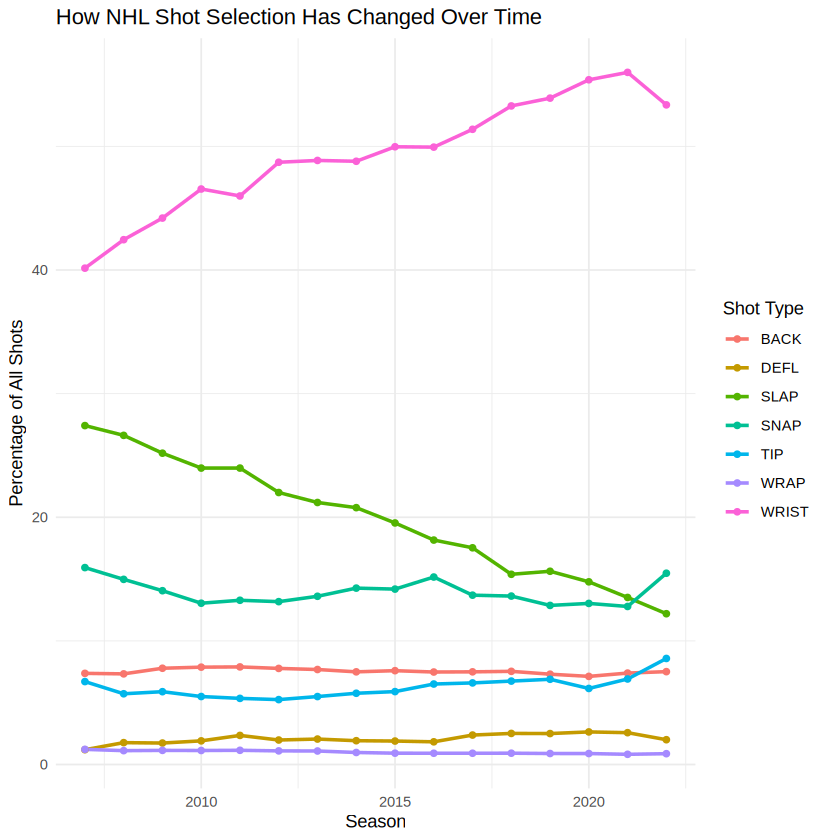

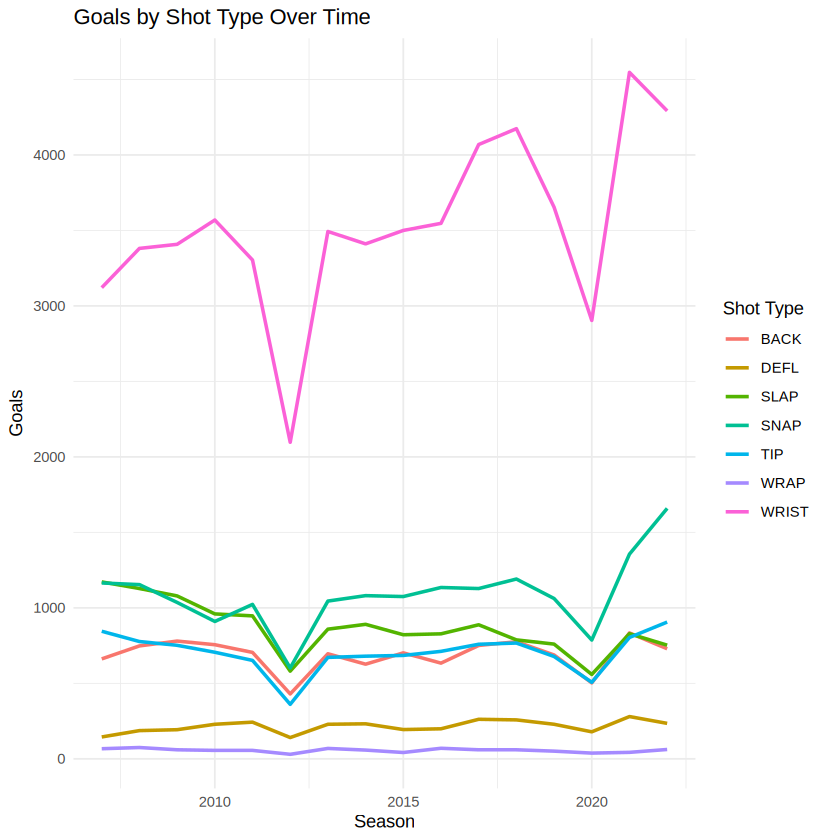

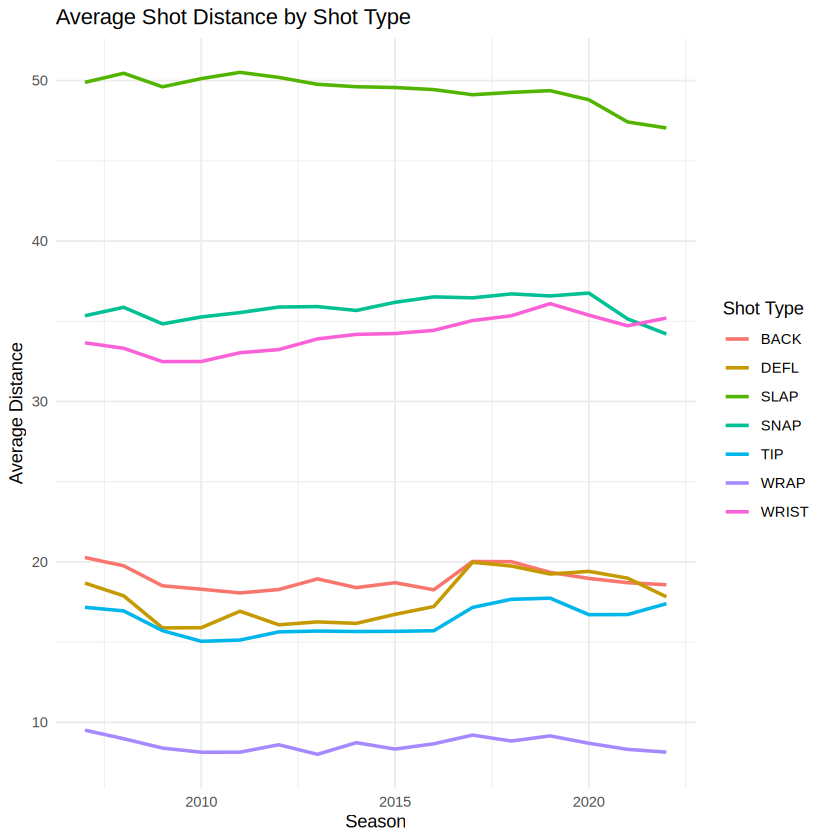

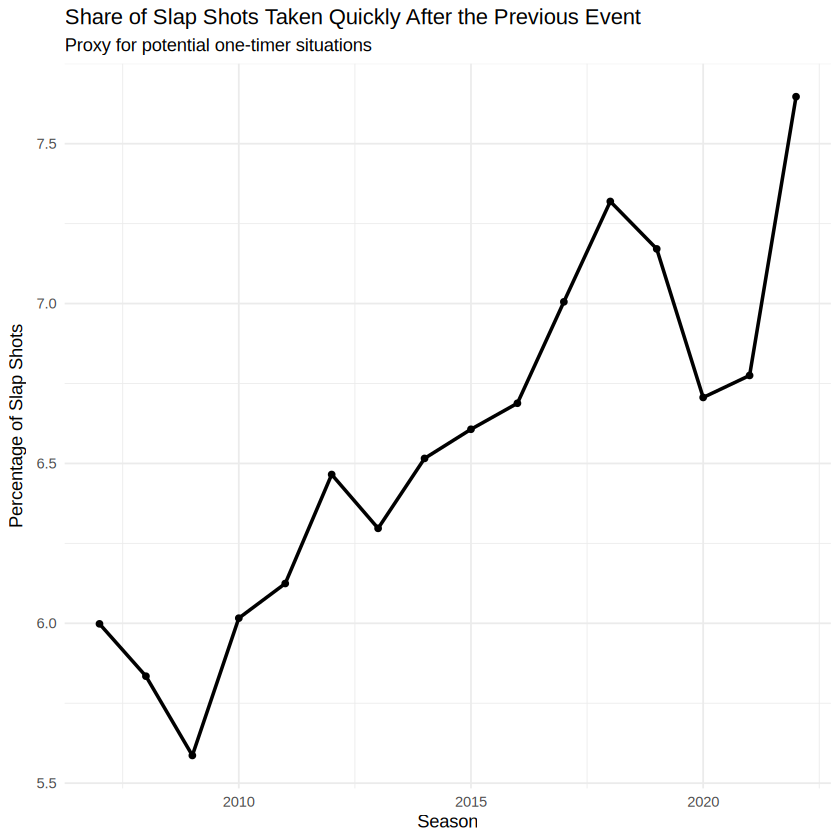

In [3]:
# Analyzing shot types year over year

shots_analysis <- df %>%
  select(
    season,
    shotType,
    goal,
    xGoal,
    shotDistance,
    isPlayoffGame,
    period,
    shotRush,
    shotRebound,
    timeSinceLastEvent,
    lastEventCategory,
    shotAngle,
    homeSkatersOnIce,
    awaySkatersOnIce,
    isHomeTeam
  ) %>%
  filter(!is.na(shotType), shotType != "")


#Calculate shot share by season
shot_share_by_season <- shots_analysis %>%
  group_by(season, shotType) %>%
  summarise(
    shots = n(),
    .groups = "drop"
  ) %>%
  group_by(season) %>%
  mutate(
    total_shots = sum(shots),
    shot_share = 100 * shots / total_shots
  ) %>%
  ungroup()
#Plot shot share over time
ggplot(
  shot_share_by_season,
  aes(
    x = season,
    y = shot_share,
    color = shotType,
    group = shotType
  )
) +
  geom_line(linewidth = 1) +
  geom_point(size = 1.5) +
  labs(
    title = "How NHL Shot Selection Has Changed Over Time",
    x = "Season",
    y = "Percentage of All Shots",
    color = "Shot Type"
  ) +
  theme_minimal()


#summary statistics
shot_type_summary <- shots_analysis %>%
  group_by(season, shotType) %>%
  summarise(
    shots = n(),
    goals = sum(goal, na.rm = TRUE),
    total_xG = sum(xGoal, na.rm = TRUE),
    avg_xG = mean(xGoal, na.rm = TRUE),
    avg_distance = mean(shotDistance, na.rm = TRUE),
    median_distance = median(shotDistance, na.rm = TRUE),
    shooting_pct = 100 * goals / shots,
    .groups = "drop"
  )


#Goals by shot type
ggplot(
  shot_type_summary,
  aes(x = season, y = goals, color = shotType, group = shotType)
) +
  geom_line(linewidth = 1) +
  labs(
    title = "Goals by Shot Type Over Time",
    x = "Season",
    y = "Goals",
    color = "Shot Type"
  ) +
  theme_minimal()
#Average shot distance by shot type
ggplot(
  shot_type_summary,
  aes(x = season, y = avg_distance, color = shotType, group = shotType)
) +
  geom_line(linewidth = 1) +
  labs(
    title = "Average Shot Distance by Shot Type",
    x = "Season",
    y = "Average Distance",
    color = "Shot Type"
  ) +
  theme_minimal()

#One-timer experiment
# This data is a proxy due to limitations with the dataset, but I believe it
# gives a pretty good idea
one_timer_proxy <- shots_analysis %>%
  filter(shotType == "SLAP") %>%
  mutate(
    possible_one_timer = timeSinceLastEvent <= 2
  )
one_timer_by_season <- one_timer_proxy %>%
  group_by(season) %>%
  summarise(
    slap_shots = n(),
    possible_one_timers = sum(possible_one_timer, na.rm = TRUE),
    one_timer_share = 100 * possible_one_timers / slap_shots,
    .groups = "drop"
  )

  ggplot(
  one_timer_by_season,
  aes(x = season, y = one_timer_share)
) +
  geom_line(linewidth = 1) +
  geom_point() +
  labs(
    title = "Share of Slap Shots Taken Quickly After the Previous Event",
    subtitle = "Proxy for potential one-timer situations",
    x = "Season",
    y = "Percentage of Slap Shots"
  ) +
  theme_minimal()


In [4]:
# You have gotta be kidding me here... all of this data but nothing for a pass??
shots_analysis %>%
  count(lastEventCategory, sort = TRUE)

lastEventCategory,n
<chr>,<int>
FAC,440721
HIT,324025
SHOT,323422
BLOCK,191467
MISS,165481
GIVE,152790
TAKE,115680
DELPEN,1684
PENL,712


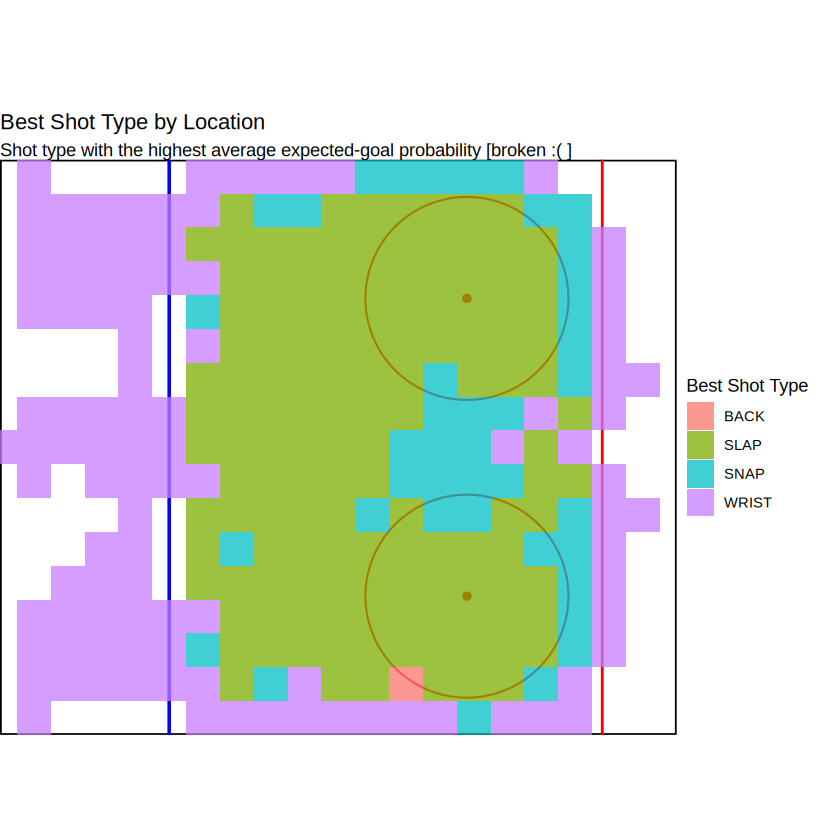

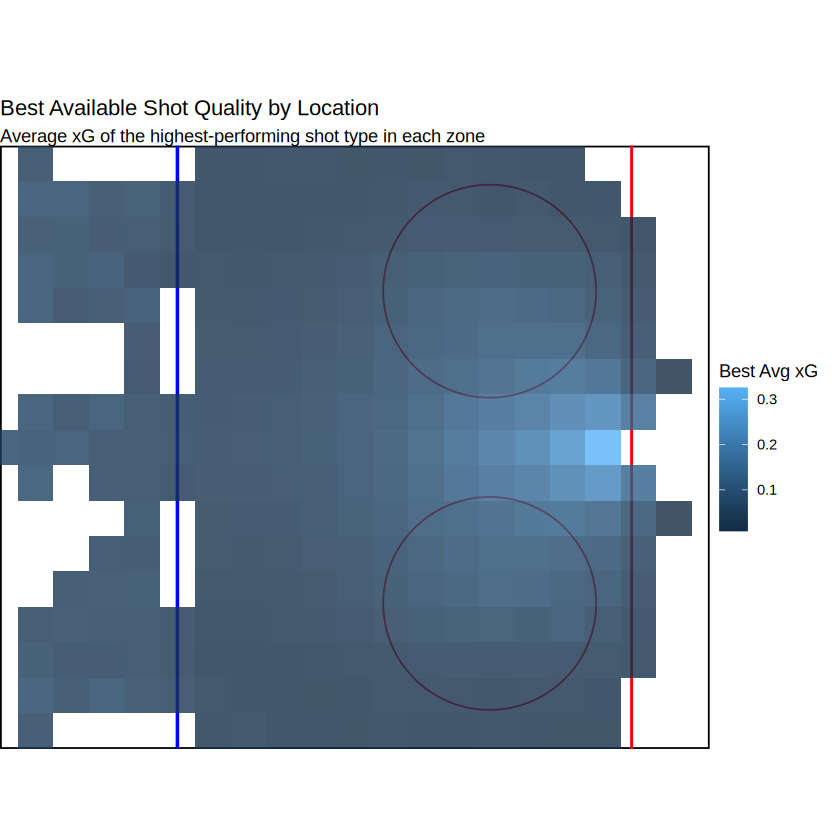

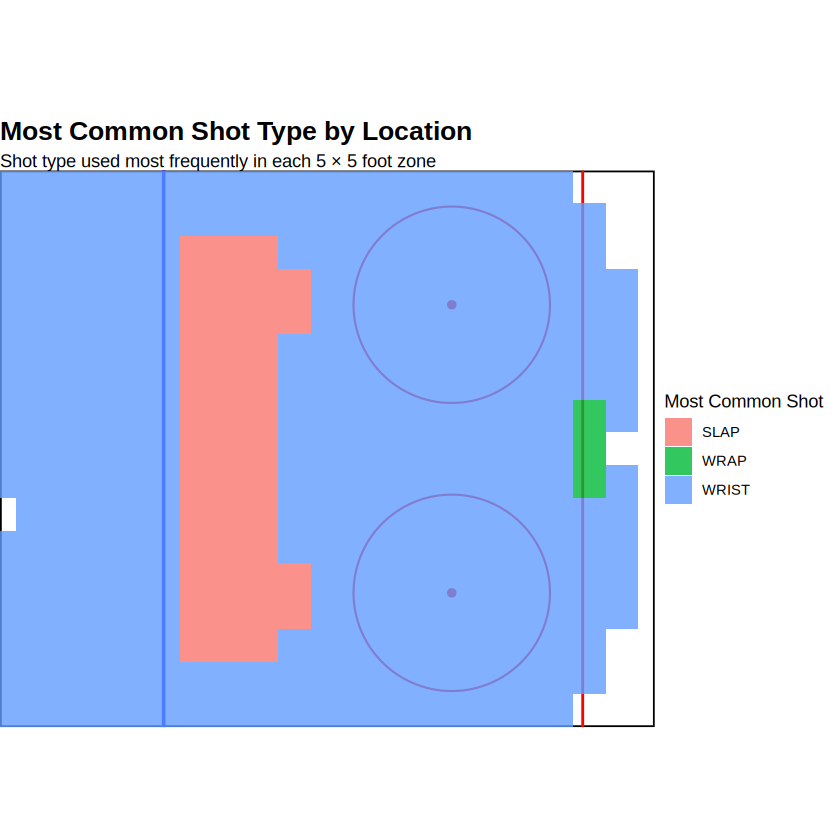

In [5]:
#shot-type/location summary
shot_type_heatmap <- df %>%
  filter(
    !is.na(xCordAdjusted),
    !is.na(yCordAdjusted),
    !is.na(xGoal),
    !is.na(goal),
    !is.na(shotType),
    shotType != ""
  ) %>%
  mutate(
    x_bin = round(xCordAdjusted / 5) * 5,
    y_bin = round(yCordAdjusted / 5) * 5
  ) %>%
  group_by(x_bin, y_bin, shotType) %>%
  summarise(
    shots = n(),
    goals = sum(goal, na.rm = TRUE),
    shooting_pct = goals / shots,
    avg_xG = mean(xGoal, na.rm = TRUE),
    .groups = "drop"
  )

  shot_type_heatmap <- shot_type_heatmap %>%
  #filter(shots >= 50) # yea so that was too small...
  filter(shots >= 200)

  best_shot_by_zone <- shot_type_heatmap %>%
  group_by(x_bin, y_bin) %>%
  slice_max(
    order_by = avg_xG,
    n = 1,
    with_ties = FALSE
  ) %>%
  ungroup()


ggplot() +

  #rink attempt (this was generated, I am not that artistic)
  geom_rect(
    aes(xmin = 0, xmax = 100, ymin = -42.5, ymax = 42.5),
    fill = "white",
    color = "black",
    linewidth = 1
  ) +

  geom_segment(
    aes(x = 25, xend = 25, y = -42.5, yend = 42.5),
    color = "blue",
    linewidth = 1
  ) +

  geom_segment(
    aes(x = 89, xend = 89, y = -42.5, yend = 42.5),
    color = "red",
    linewidth = 0.8
  ) +

  ggforce::geom_circle(
    aes(x0 = 69, y0 = 22, r = 15),
    color = "red",
    fill = NA,
    linewidth = 0.6
  ) +

  ggforce::geom_circle(
    aes(x0 = 69, y0 = -22, r = 15),
    color = "red",
    fill = NA,
    linewidth = 0.6
  ) +

  annotate(
    "point",
    x = c(69, 69),
    y = c(22, -22),
    color = "red",
    size = 2
  ) +

  #Best shot type by zone
  # I don't really believe the data here
  geom_tile(
    data = best_shot_by_zone,
    aes(
      x = x_bin,
      y = y_bin,
      fill = shotType
    ),
    width = 5,
    height = 5,
    alpha = 0.75
  ) +

  coord_fixed(
    xlim = c(0, 100),
    ylim = c(-42.5, 42.5),
    expand = FALSE
  ) +

  labs(
    title = "Best Shot Type by Location",
    subtitle = "Shot type with the highest average expected-goal probability [broken :( ]",
    x = NULL,
    y = NULL,
    fill = "Best Shot Type"
  ) +

  theme_void()


 ggplot() +

  geom_rect(
    aes(xmin = 0, xmax = 100, ymin = -42.5, ymax = 42.5),
    fill = "white",
    color = "black",
    linewidth = 1
  ) +

  geom_segment(
    aes(x = 25, xend = 25, y = -42.5, yend = 42.5),
    color = "blue",
    linewidth = 1
  ) +

  geom_segment(
    aes(x = 89, xend = 89, y = -42.5, yend = 42.5),
    color = "red",
    linewidth = 0.8
  ) +

  ggforce::geom_circle(
    aes(x0 = 69, y0 = 22, r = 15),
    color = "red",
    fill = NA
  ) +

  ggforce::geom_circle(
    aes(x0 = 69, y0 = -22, r = 15),
    color = "red",
    fill = NA
  ) +

  geom_tile(
    data = best_shot_by_zone,
    aes(
      x = x_bin,
      y = y_bin,
      fill = avg_xG
    ),
    width = 5,
    height = 5,
    alpha = 0.8
  ) +

  coord_fixed(
    xlim = c(0, 100),
    ylim = c(-42.5, 42.5),
    expand = FALSE
  ) +

  labs(
    title = "Best Available Shot Quality by Location",
    subtitle = "Average xG of the highest-performing shot type in each zone",
    x = NULL,
    y = NULL,
    fill = "Best Avg xG"
  ) +

  theme_void()


  # Most frequently used shot type in each area of the ice
  # this is believable

shot_frequency_by_zone <- df %>%
  filter(
    !is.na(xCordAdjusted),
    !is.na(yCordAdjusted),
    !is.na(shotType),
    shotType != ""
  ) %>%
  mutate(
    x_bin = round(xCordAdjusted / 5) * 5,
    y_bin = round(yCordAdjusted / 5) * 5
  ) %>%
  group_by(x_bin, y_bin, shotType) %>%
  summarise(
    shots = n(),
    .groups = "drop"
  )

  shot_frequency_by_zone <- shot_frequency_by_zone %>%
  group_by(x_bin, y_bin) %>%
  mutate(
    total_zone_shots = sum(shots),
    shot_type_share = 100 * shots / total_zone_shots
  ) %>%
  ungroup()

  shot_frequency_by_zone <- shot_frequency_by_zone %>%
  filter(total_zone_shots >= 100)

  most_common_shot_by_zone <- shot_frequency_by_zone %>%
  group_by(x_bin, y_bin) %>%
  slice_max(
    order_by = shots,
    n = 1,
    with_ties = FALSE
  ) %>%
  ungroup()

  ggplot() +

  # Rink (generated again)
  geom_rect(
    aes(xmin = 0, xmax = 100, ymin = -42.5, ymax = 42.5),
    fill = "white",
    color = "black",
    linewidth = 1
  ) +
  geom_segment(
    aes(x = 25, xend = 25, y = -42.5, yend = 42.5),
    color = "blue",
    linewidth = 1
  ) +
  geom_segment(
    aes(x = 89, xend = 89, y = -42.5, yend = 42.5),
    color = "red",
    linewidth = 0.8
  ) +
  ggforce::geom_circle(
    aes(x0 = 69, y0 = 22, r = 15),
    color = "red",
    fill = NA,
    linewidth = 0.6
  ) +

  ggforce::geom_circle(
    aes(x0 = 69, y0 = -22, r = 15),
    color = "red",
    fill = NA,
    linewidth = 0.6
  ) +
  annotate(
    "point",
    x = c(69, 69),
    y = c(22, -22),
    color = "red",
    size = 2
  ) +
  geom_tile(
    data = most_common_shot_by_zone,
    aes(
      x = x_bin,
      y = y_bin,
      fill = shotType
    ),
    width = 5,
    height = 5,
    alpha = 0.8
  ) +

  coord_fixed(
    xlim = c(0, 100),
    ylim = c(-42.5, 42.5),
    expand = FALSE
  ) +

  labs(
    title = "Most Common Shot Type by Location",
    subtitle = "Shot type used most frequently in each 5 × 5 foot zone",
    x = NULL,
    y = NULL,
    fill = "Most Common Shot"
  ) +

  theme_void() +

  theme(
    plot.title = element_text(size = 16, face = "bold"),
    plot.subtitle = element_text(size = 11),
    legend.position = "right"
  )

The text below this code chunk will should explain anything you notice or want to point out based on what you ran above. You should also explain where you're heading next in your analysis and why. As you continue with your analysis, you can alternate between code chunks (including code comments) and text cells. Keep going until you're happy with the amount of analysis and/or you have an answer to your question. Within your exploration, you should include **a minimum of one visualization** and explain your choice of visualization.

5. **Limitations**: 100-200 words. Explain the limitations of your chosen dataset in answering the question you have identified.

- HOW IS THERE NO PASS FOR THE DATA RIGHT BEFORE?!?!?!
- How are they defining slapshot?? The heat map of expected goals by different shots on the ice is a terrible data story. It makes zero sense at all...

6. **Additional Directions/New Questions**: 100 words. Suggest additional directions or new questions that might be explored with additional information, explaining what that information might include and where it might be collected or found.

- Goalie tendancies. Combining two datasets matching by shotID if it exists. Lefty vs righty goalies. Lefty vs righty players. Individual player / team tendancies. How to fix that slapshot problem? Bayes theorem?
- Likelihood to get a shot off / shot on goal from an attempt! A slapshot two feet from the net doesn't make sense. Yea I guess it would be likely to score, good luck attempting that though...